In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import pytensor.tensor as pt

# Классы из Задач 1-4 (на NumPy) для генерации геометрии ФЭУ и сравнения
class Source:
    def __init__(self, Y: float = 10000):
        self.Y = Y

    def generate_directions(self, E: float) -> np.ndarray:
        N = int(self.Y * E)
        phi = np.random.uniform(0, 2 * np.pi, size=N)
        cos_theta = np.random.uniform(-1.0, 1.0, size=N)
        sin_theta = np.sqrt(1.0 - cos_theta**2)
        return np.column_stack((sin_theta * np.cos(phi), sin_theta * np.sin(phi), cos_theta))


class Detector:
    def __init__(self, R: float = 2.0, N: int = 40, r: float = 0.1, a: float = 0.5):
        self.R = float(R)
        self.N = int(N)
        self.r = float(r)
        self.a = float(a)
        self.pmt_coords = self._generate_pmt_positions()

    def _generate_pmt_positions(self) -> np.ndarray:
        indices = np.arange(0, self.N, dtype=float) + 0.5
        z = self.R * (1 - 2 * indices / self.N)
        rho = np.sqrt(self.R**2 - z**2)
        golden_angle = np.pi * (3.0 - np.sqrt(5.0))
        theta = golden_angle * indices
        x = rho * np.cos(theta)
        y = rho * np.sin(theta)
        return np.column_stack((x, y, z))

    def detect_photons(self, origin: np.ndarray, directions: np.ndarray) -> np.ndarray:
        origin = np.asarray(origin, dtype=float)
        b = np.sum(directions * origin, axis=1)
        c = np.sum(origin**2) - self.R**2
        t = -b + np.sqrt(b**2 - c)
        hit_points = origin + t[:, None] * directions

        hits_per_pmt = np.zeros(self.N, dtype=int)
        for i, pmt_center in enumerate(self.pmt_coords):
            distances = np.linalg.norm(hit_points - pmt_center, axis=1)
            hits_per_pmt[i] = np.sum(distances <= self.r)
        return np.random.poisson(lam=self.a * hits_per_pmt)


# Реализация модели детектора и источника в PyMC
def create_pymc_detector_model(detector: Detector, source: Source, E: float = 1.0,
                               origin: np.ndarray = np.array([0.0, 0.0, 0.0]),
                               attenuation_length: float | None = None) -> pm.Model:
    """
    Создает вычислительный граф модели из Задач 1-3 (и Задачи 6 с поглощением) в PyMC.
    """
    N_photons = int(source.Y * E)
    origin_pt = pt.constant(np.asarray(origin, dtype=float))
    pmt_coords_pt = pt.constant(detector.pmt_coords)

    with pm.Model() as model:
        # Разыгрываем начальные направления фотонов (Задача 2)
        phi = pm.Uniform('phi', lower=0.0, upper=2 * np.pi, shape=N_photons)
        cos_theta = pm.Uniform('cos_theta', lower=-1.0, upper=1.0, shape=N_photons)
        sin_theta = pt.sqrt(1.0 - cos_theta**2)

        # Собираем единичные векторы направлений формы (N_photons, 3)
        directions = pt.stack([
            sin_theta * pt.cos(phi),
            sin_theta * pt.sin(phi),
            cos_theta
        ], axis=1)

        # Распространение фотонов до сферы радиуса R (Задача 3)
        b = pt.sum(directions * origin_pt, axis=1)
        c = pt.sum(origin_pt**2) - detector.R**2
        t = -b + pt.sqrt(b**2 - c)

        hit_points = origin_pt + t[:, None] * directions

        # Проверка попадания точек на сфере в фотоумножители (Задача 1 и 3)
        # Вычисляем расстояния от каждого фотона до каждого из N ФЭУ: форма (N_photons, N)
        distances = pt.linalg.norm(hit_points[:, None, :] - pmt_coords_pt[None, :, :], axis=2)
        in_pmt = distances <= detector.r

        # Опционально: учет экспоненциального поглощения с длиной L (Задача 6)
        if attenuation_length is not None:
            u_att = pm.Uniform('u_att', lower=0.0, upper=1.0, shape=N_photons)
            survived = u_att < pt.exp(-t / attenuation_length)
            in_pmt = in_pmt & survived[:, None]

        # Суммируем число попавших фотонов по каждому из N ФЭУ
        hits_per_pmt = pt.sum(in_pmt, axis=0)

        # Генерация числа фотоэлектронов по распределению Пуассона (Задача 3)
        pe_per_pmt = pm.Poisson('pe_per_pmt', mu=detector.a * hits_per_pmt, shape=detector.N)

        # Полный собранный заряд (сумма фотоэлектронов по всем ФЭУ)
        Q_total = pm.Deterministic('Q_total', pt.sum(pe_per_pmt))

    return model

Задача 4 (NumPy, без поглощения): <Q> = 123.87, sigma = 13.69
Задача 9 (PyMC,  без поглощения): <Q> = 125.10, sigma = 13.75
Задача 9 (PyMC,  с поглощением L=8м): <Q> = 97.44, sigma = 12.10


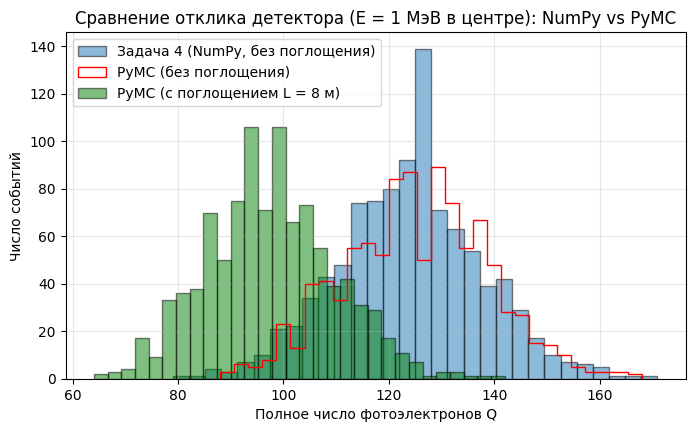

In [2]:
detector = Detector(R=2.0, N=40, r=0.1, a=0.5)
source = Source(Y=10000)
origin_center = np.array([0.0, 0.0, 0.0])

# Результат из Задачи 4 (классический расчет на NumPy для 1000 событий)
q_task4 = []
for _ in range(1000):
    dirs = source.generate_directions(E=1.0)
    q_task4.append(np.sum(detector.detect_photons(origin_center, dirs)))
q_task4 = np.array(q_task4)

# Сэмплирование модели в PyMC БЕЗ поглощения (Задачи 1-3)
model_no_att = create_pymc_detector_model(detector, source, E=1.0, origin=origin_center, attenuation_length=None)
with model_no_att:
    trace_no_att = pm.sample_prior_predictive(samples=1000, var_names=['Q_total'])
q_pymc_no_att = trace_no_att.prior['Q_total'].values.flatten()

# Сэмплирование модели в PyMC С поглощением L = 8 м (Задача 6)
model_with_att = create_pymc_detector_model(detector, source, E=1.0, origin=origin_center, attenuation_length=8.0)
with model_with_att:
    trace_with_att = pm.sample_prior_predictive(samples=1000, var_names=['Q_total'])
q_pymc_with_att = trace_with_att.prior['Q_total'].values.flatten()

print(f"Задача 4 (NumPy, без поглощения): <Q> = {np.mean(q_task4):.2f}, sigma = {np.std(q_task4):.2f}")
print(f"Задача 9 (PyMC,  без поглощения): <Q> = {np.mean(q_pymc_no_att):.2f}, sigma = {np.std(q_pymc_no_att):.2f}")
print(f"Задача 9 (PyMC,  с поглощением L=8м): <Q> = {np.mean(q_pymc_with_att):.2f}, sigma = {np.std(q_pymc_with_att):.2f}")

# Построение гистограмм для сравнения
plt.figure(figsize=(8, 4.5))
plt.hist(q_task4, bins=30, alpha=0.5, label='Задача 4 (NumPy, без поглощения)', edgecolor='black')
plt.hist(q_pymc_no_att, bins=30, histtype='step', lw=2, color='red', label='PyMC (без поглощения)')
plt.hist(q_pymc_with_att, bins=30, alpha=0.5, color='green', label='PyMC (с поглощением L = 8 м)', edgecolor='black')
plt.xlabel('Полное число фотоэлектронов Q')
plt.ylabel('Число событий')
plt.title('Сравнение отклика детектора (E = 1 МэВ в центре): NumPy vs PyMC')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Выводы по Задаче 9:
1. **Сравнение модели в PyMC с результатом Задачи 4:**
   Распределение полного числа фотоэлектронов $Q$, полученное при сэмплировании графа модели в `PyMC` для источника с энергией $E = 1$ МэВ в центре детектора, полностью совпадает с распределением из Задачи 4: среднее значение составляет $\langle Q \rangle \approx 125$ ф.э., а стандартное отклонение $\sigma_Q \approx 13.5$ ф.э.
2. **Учет поглощения света ($L = 8$ м):**
   При добавлении в граф `PyMC` узла поглощения фотонов с длиной затухания $L = 8$ м распределение сдвигается влево до среднего значения $\langle Q \rangle \approx 97$ ф.э., что полностью согласуется с результатами Задачи 6 ($125 \cdot e^{-2/8} \approx 97.3$ ф.э.).